# 04 Test: the models on the test period, once

**Purpose:** Evaluate the final model, chosen on the backtest only (`03_evaluate.ipynb`, section 10), on the test period (2024-10 to 2026-09), together with the simple rules and every other candidate of both model families, all in one table. This is the only notebook that uses the test period.
**Input:** `../data/processed/asylum_clean.csv`, `routes_clean.csv`, `neighbours_clean.csv`, `nationality_shares_clean.csv`, `conflict_intensity_clean.csv`, and `../output/tables/03_backtest_errors.csv` and `03_two_models.csv` (from `03_evaluate.ipynb`).
**Output:** `../data/processed/test_forecasts.csv`, `../output/tables/04_test_errors.csv` and `../output/figures/04_test_forecasts_h2.png`.

**The choice was made before the test** (notebook 209, Step 7): the linear regression on the series' own past. The other models are shown next to it so that the whole comparison is visible; we do not change the choice after seeing the results below (notebook 209, Step 8).

**Timeline.** The group fixed the choice rule and chose the linear regression on 17 November 2026 (commit `c6a3976`), then ran the test once (commit `4f284f5`). The random walk, the neighbouring countries, the conflict index and the one-year horizon (`02e`) were added afterwards, on the backtest only. The rule was not changed, and it still chooses the linear regression (`03`, section 10), so the test result of the chosen model is the same as in the first run.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the whole series

For the first time, we use all 225 months, including the 24 months of the test period.

In [2]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")

y = clean["applicants_total"].to_numpy(dtype=float)
log_y = clean["log_applicants"].to_numpy(dtype=float)
months = clean.index

last_backtest = int(np.where(months == pd.Timestamp("2024-09-01"))[0][0])
last_month = len(months) - 1
H_MAX = 3

print(clean["period"].value_counts())
print("Last backtest month:", months[last_backtest], "| last month:", months[last_month])

def load(path):
    data = pd.read_csv(path)
    data["month"] = pd.to_datetime(data["month"])
    return data.set_index("month")

log_routes = load("../data/processed/routes_clean.csv")["log_routes"].reindex(months).to_numpy(dtype=float)
log_neighbours = load("../data/processed/neighbours_clean.csv")["log_neighbours"].reindex(months).to_numpy(dtype=float)
shares = load("../data/processed/nationality_shares_clean.csv").reindex(months)
intensity = load("../data/processed/conflict_intensity_clean.csv")

period
backtest    141
training     60
test         24
Name: count, dtype: int64
Last backtest month: 2024-09-01 00:00:00 | last month: 2026-09-01 00:00:00


## 2. The models, exactly as in the backtest

- **Simple rules** (`02_estimate.ipynb`): the 12-month average (the best simple baseline of our plan) and the random walk (the last known month).
- **Family 1** (`02b`): linear regression (our chosen model), Ridge and Lasso on the series' own past.
- **Family 2** (`02c`): the same three regressions with each indicator (routes, neighbouring countries, conflict index) and with all three. The lag of the conflict index (GDELT) is chosen at each origin as in the backtest.

The functions are copied from `02`, `02b` and `02c` without any change; first we check that the copy gives exactly the stored backtest forecasts at the last backtest origin.

In [3]:
features = {   # copied from 02c
    "routes": {"routes_change_last_month": lambda t: log_routes[t - 1] - log_routes[t - 2],
               "routes_change_3_months": lambda t: log_routes[t - 1] - log_routes[t - 4]},
    "neighbours": {"neighbours_change_last_month": lambda t: log_neighbours[t - 1] - log_neighbours[t - 2],
                   "neighbours_change_3_months": lambda t: log_neighbours[t - 1] - log_neighbours[t - 4]},
}
def conflict_change(t, L, k):
    # Copied from 02c
    w = shares.iloc[t]
    if w.isna().all():
        return np.nan
    top = w.nlargest(10)
    m1 = months[t] - pd.DateOffset(months=L)
    m0 = months[t] - pd.DateOffset(months=L + k)
    if m1 not in intensity.index or m0 not in intensity.index:
        return np.nan
    weighted = top * (intensity.loc[m1, top.index] - intensity.loc[m0, top.index])
    return float(weighted.sum()) if weighted.notna().all() else np.nan

LAGS = range(0, 13)
conflict = {(L, k): np.array([conflict_change(t, L, k) for t in range(len(months))]) for L in LAGS for k in [3, 6]}

def block_features(block, L):
    if block == "conflict":
        return {"conflict_3_months": lambda t: conflict[(L, 3)][t], "conflict_6_months": lambda t: conflict[(L, 6)][t]}
    return features[block]

combinations = {"": [], " + routes": ["routes"], " + neighbours": ["neighbours"], " + conflict": ["conflict"],
                " + all indicators": ["routes", "neighbours", "conflict"]}

def make_table(h, parts, L=None):
    # Copied from 02c; with no indicator it is the table of 02b
    extra_features = {k: f for b in parts for k, f in block_features(b, L).items()}
    rows = []
    for t in range(12, len(log_y) - h):
        values = {name: f(t) for name, f in extra_features.items()}
        if any(np.isnan(v) for v in values.values()):
            continue
        rows.append({"t": t,
                     "change_last_month": log_y[t] - log_y[t - 1],
                     "change_month_before": log_y[t - 1] - log_y[t - 2],
                     "same_change_last_year": log_y[t + h - 12] - log_y[t - 12],
                     **values,
                     "calendar_month": months[t + h].month,
                     "target": log_y[t + h] - log_y[t]})
    table = pd.DataFrame(rows).set_index("t")
    dummies = pd.get_dummies(table["calendar_month"], prefix="month", drop_first=True).astype(float)
    names = ["change_last_month", "change_month_before", "same_change_last_year"] + list(extra_features)
    return pd.concat([table[names], dummies], axis=1), table["target"]

def make_model(name, alpha=None):
    # Copied from 02b
    if name == "Linear regression":
        return make_pipeline(StandardScaler(), LinearRegression())
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    return make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=10000))

alpha_grids = {"Linear regression": [None], "Ridge": [0.1, 1, 10, 100, 1000, 10000],
               "Lasso": [0.0001, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3]}

def validation_mse(name, alpha, X, target, T, h, n_blocks=2, block=12):
    # Copied from 02c
    first_row, last_row = X.index.min(), T - h
    mse_blocks = []
    for b in range(n_blocks):
        start = last_row - n_blocks * block + 1 + b * block
        valid_rows = list(range(start, start + block))
        train_rows = list(range(first_row, start - h + 1))
        model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
        errors = target.loc[valid_rows].to_numpy() - model.predict(X.loc[valid_rows])
        mse_blocks.append(np.mean(errors ** 2))
    return np.mean(mse_blocks)

def choose_alpha(name, X, target, T, h):
    grid = alpha_grids[name]
    if len(grid) == 1:
        return grid[0]
    return grid[int(np.argmin([validation_mse(name, alpha, X, target, T, h) for alpha in grid]))]

def choose_lag(suffix, T, h):
    # Copied from 02c: only lags whose months exist at the origin T can be chosen
    scores = {}
    for L in LAGS:
        X, target = tables[(suffix, h, L)]
        if T in X.index:
            scores[L] = validation_mse("Linear regression", None, X, target, T, h)
    return min(scores, key=scores.get)

def average_12(train_y, h_max):
    # Copied from 02: average of the last 12 known months, the same for every horizon
    return np.log(np.full(h_max, train_y[-12:].mean()))

tables = {(suffix, h, L): make_table(h, parts, L) for suffix, parts in combinations.items() for h in range(1, H_MAX + 1)
          for L in (LAGS if "conflict" in parts else [None])}
chosen_lags = {}

def regression_forecast(name, suffix, t, h):
    # one forecast of log applications at origin t, refitted on the months known at t
    if "conflict" in combinations[suffix]:
        if (suffix, t, h) not in chosen_lags:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                chosen_lags[(suffix, t, h)] = choose_lag(suffix, t, h)
        L = chosen_lags[(suffix, t, h)]
    else:
        L = None
    X, target = tables[(suffix, h, L)]
    train_rows = list(range(X.index.min(), t - h + 1))
    assert max(train_rows) + h <= t                       # no training target after the origin
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        alpha = choose_alpha(name, X, target, t, h)
        model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
    return log_y[t] + model.predict(X.loc[[t]])[0]

# Check the copy at the last backtest origin (2024-08, h = 1)
stored = pd.concat([pd.read_csv("../data/processed/backtest_forecasts_regression.csv"),
                    pd.read_csv("../data/processed/backtest_forecasts_indicator.csv")])
for name in alpha_grids:
    for suffix in combinations:
        s = stored[(stored["model"] == name + suffix) & (stored["origin"] == str(months[last_backtest - 1].date())) & (stored["h"] == 1)]
        assert np.isclose(regression_forecast(name, suffix, last_backtest - 1, 1), s["forecast_log"].iloc[0]), name + suffix
print("The copied functions reproduce the stored backtest forecasts of all", len(alpha_grids) * len(combinations), "regressions.")

The copied functions reproduce the stored backtest forecasts of all 15 regressions.


## 3. Forecasts for the test period

We continue the backtest into the test period with the same rule: at each origin, the models are fitted on **all months known at that origin and nothing after it**, and we forecast $h = 1, 2, 3$. The origins go from September 2024 (the last backtest month) to August 2026. So the forecasts for, say, March 2026 are made with the months up to December 2025 ($h = 3$), January 2026 ($h = 2$) or February 2026 ($h = 1$), as a planner would have had them.

This is the time-series version of "refit on all training data, then test" (notebook 209, Step 8): there is no single refit, because in practice the model is refitted every month when a new number arrives. We expect 24 forecasts for $h = 1$, 23 for $h = 2$ and 22 for $h = 3$ per model.

In [4]:
rows = []
for t in range(last_backtest, last_month):          # origins 2024-09 to 2026-08
    for h in range(1, H_MAX + 1):
        target_pos = t + h
        if target_pos > last_month:
            continue
        logs = {"12-month average": average_12(y[: t + 1], H_MAX)[h - 1], "Random walk": log_y[t]}
        for name in alpha_grids:
            for suffix in combinations:
                logs[name + suffix] = regression_forecast(name, suffix, t, h)
        for name, forecast_log in logs.items():
            rows.append({"model": name, "origin": months[t], "month": months[target_pos], "h": h,
                         "forecast_log": forecast_log, "actual_log": log_y[target_pos],
                         "forecast": np.exp(forecast_log), "actual": y[target_pos]})

test_forecasts = pd.DataFrame(rows)
print(test_forecasts.groupby("h").size() / test_forecasts["model"].nunique(), "forecasts per model and horizon;",
      test_forecasts["model"].nunique(), "models")
print("All forecast months in the test period:", (test_forecasts["month"] >= pd.Timestamp("2024-10-01")).all())
print("All forecast months after their origin:", (test_forecasts["month"] > test_forecasts["origin"]).all())
print("Missing or infinite forecasts:", (~np.isfinite(test_forecasts["forecast_log"])).sum())
print("Lags of the conflict index chosen at the test origins (all indicators, h = 2):",
      [v for k, v in sorted(chosen_lags.items()) if k[0] == " + all indicators" and k[2] == 2])

h
1    24.0
2    23.0
3    22.0
dtype: float64 forecasts per model and horizon; 17 models
All forecast months in the test period: True
All forecast months after their origin: True
Missing or infinite forecasts: 0
Lags of the conflict index chosen at the test origins (all indicators, h = 2): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 7, 7, 0, 0, 0, 0, 0, 0, 3]


**What we see.** Each model has 24 forecasts for $h = 1$, 23 for $h = 2$ and 22 for $h = 3$, as expected. All forecast months lie in the test period and after their origin, and no forecast is missing. Together with the `assert` in the loop, this shows that each forecast used only the months known at its origin.

## 4. Test errors

The same two error measures as in `03_evaluate.ipynb`: the MAE in persons (main) and the RMSE in logs.

In [5]:
test_forecasts["abs_error"] = (test_forecasts["actual"] - test_forecasts["forecast"]).abs()
test_forecasts["sq_error_log"] = (test_forecasts["actual_log"] - test_forecasts["forecast_log"]) ** 2

grouped = test_forecasts.groupby(["model", "h"])
test_errors = pd.DataFrame({
    "MAE (persons)": grouped["abs_error"].mean(),
    "MSE (log)": grouped["sq_error_log"].mean(),
    "RMSE (log)": np.sqrt(grouped["sq_error_log"].mean()),
    "forecasts": grouped["abs_error"].size(),
}).reset_index()
test_errors.to_csv("../output/tables/04_test_errors.csv", index=False)

order = ["12-month average", "Random walk"] + [n + s for s in combinations for n in alpha_grids]
table = test_errors.pivot(index="model", columns="h", values="MAE (persons)").loc[order].round(0)
table.columns = [f"MAE h={h}" for h in table.columns]
table["MSE log h=2"] = test_errors[test_errors["h"] == 2].set_index("model").loc[order, "MSE (log)"].round(4)
table

,MAE h=1,MAE h=2,MAE h=3,MSE log h=2
model,,,,
12-month average,297.0,331.0,359.0,0.0365
Random walk,187.0,269.0,358.0,0.0258
Linear regression,149.0,188.0,217.0,0.0126
Ridge,130.0,192.0,222.0,0.0131
Lasso,152.0,192.0,217.0,0.0144
Linear regression + routes,151.0,197.0,227.0,0.0125
Ridge + routes,128.0,193.0,218.0,0.0131
Lasso + routes,150.0,193.0,224.0,0.0126
Linear regression + neighbours,154.0,194.0,228.0,0.0128


**What we see.** All models have 24, 23 and 22 test forecasts at $h = 1, 2, 3$. At $h = 2$ the chosen linear regression has an MAE of 188 persons, the random walk 269, the 12-month average 331. The other regressions lie between 186 (Ridge with the neighbours) and 213 (Lasso with the neighbours); model 2 (Ridge with all indicators) is at 190, the linear regression with all indicators at 212. The test errors are about half the backtest errors, because the test months are calm (see below).

### The main comparison at $h = 2$

In [6]:
h2 = test_errors[test_errors["h"] == 2].set_index("model")
model_2 = pd.read_csv("../output/tables/03_two_models.csv").set_index("family").loc["all indicators", "model"]
mae_lr = h2.loc["Linear regression", "MAE (persons)"]
for other in ["12-month average", "Random walk", model_2]:
    mae_o = h2.loc[other, "MAE (persons)"]
    print(f"Linear regression {mae_lr:.1f} against {other} {mae_o:.1f}: {100 * (1 - mae_lr / mae_o):.0f}% lower MAE, "
          f"{100 * (1 - h2.loc['Linear regression', 'RMSE (log)'] / h2.loc[other, 'RMSE (log)']):.0f}% lower RMSE (log)")
print("Success rule of our plan (at least 10% lower MAE than the best simple baseline):",
      mae_lr <= 0.9 * h2.loc["12-month average", "MAE (persons)"])
print(f"For comparison, average actual number of applications in these months: {test_forecasts[test_forecasts['h'] == 2]['actual'].mean():.0f}")

Linear regression 188.0 against 12-month average 331.3: 43% lower MAE, 41% lower RMSE (log)
Linear regression 188.0 against Random walk 269.1: 30% lower MAE, 30% lower RMSE (log)
Linear regression 188.0 against Ridge + all indicators 189.8: 1% lower MAE, 1% lower RMSE (log)
Success rule of our plan (at least 10% lower MAE than the best simple baseline): True
For comparison, average actual number of applications in these months: 1982


**What we see.** The linear regression has a **43% lower MAE** than the 12-month average (188 against 331) and 41% lower RMSE (log); against the random walk 30% lower. Against model 2 (Ridge with all indicators, 190) the difference is only 1%. The success rule of our plan (at least 10% lower MAE than the best simple baseline) is met. For comparison, there were on average about 1,980 applications per month in these test months.

## 5. Test against backtest

How do the test errors compare with the backtest errors of the same models (from `03_evaluate.ipynb`)? The backtest error of the chosen model is a little too optimistic, because it won the comparison (notebook 108b). The two periods also differ in how hard they are: we put the average number of applications next to the errors.

In [7]:
backtest = pd.read_csv("../output/tables/03_backtest_errors.csv").set_index("model")
comparison = pd.DataFrame(index=list(dict.fromkeys(["Linear regression", "12-month average", "Random walk", model_2])))
for h in [1, 2, 3]:
    comparison[f"backtest MAE h={h}"] = backtest.loc[comparison.index, f"MAE h={h}"]
    comparison[f"test MAE h={h}"] = [test_errors[(test_errors["model"] == m) & (test_errors["h"] == h)]["MAE (persons)"].iloc[0]
                                     for m in comparison.index]
print(comparison.round(0))
print()
level = clean.groupby("period")["applicants_total"].agg(["mean", "std"]).round(0)
print("Applications per month in each period:")
print(level)

                        backtest MAE h=1  test MAE h=1  backtest MAE h=2  \
Linear regression                  256.0         149.0             358.0   
12-month average                   487.0         297.0             528.0   
Random walk                        259.0         187.0             379.0   
Ridge + all indicators             255.0         140.0             369.0   

                        test MAE h=2  backtest MAE h=3  test MAE h=3  
Linear regression              188.0             452.0         217.0  
12-month average               331.0             558.0         359.0  
Random walk                    269.0             487.0         358.0  
Ridge + all indicators         190.0             485.0         230.0  

Applications per month in each period:
            mean    std
period                 
backtest  1852.0  888.0
test      2008.0  338.0
training  1678.0  561.0


**What we see.** The test errors are much smaller than the backtest errors (188 against 358 for the linear regression at $h = 2$), for all models. The reason is the period, not the models: in the test months the applications varied much less (standard deviation 338 against 888 in the backtest), with no crisis like 2015-16 or 2022. The ranking is the same as in the backtest: linear regression and model 2 close together, then the random walk, then the 12-month average.

## 6. The forecasts two months ahead, month by month

The table shows what a planner would have seen: for each month of the test period, the forecast made two months earlier and the actual number.

In [8]:
h2_forecasts = test_forecasts[test_forecasts["h"] == 2]
monthly = h2_forecasts.pivot(index="month", columns="model", values="forecast")[["12-month average", "Linear regression", model_2]].round(0)
monthly.insert(0, "Actual", h2_forecasts.groupby("month")["actual"].first())
monthly["error of the linear regression"] = monthly["Linear regression"] - monthly["Actual"]
monthly

model,Actual,12-month average,Linear regression,Ridge + all indicators,error of the linear regression
month,,,,,
2024-11-01,2320.0,2485.0,2480.0,2645.0,160.0
2024-12-01,1850.0,2409.0,2179.0,2168.0,329.0
2025-01-01,1910.0,2341.0,2118.0,2182.0,208.0
2025-02-01,1765.0,2308.0,1702.0,1734.0,-63.0
2025-03-01,1825.0,2237.0,1642.0,1645.0,-183.0
2025-04-01,1890.0,2180.0,1573.0,1694.0,-317.0
2025-05-01,2020.0,2134.0,1723.0,1814.0,-297.0
2025-06-01,2210.0,2102.0,2270.0,2157.0,60.0
2025-07-01,2480.0,2074.0,2441.0,2413.0,-39.0


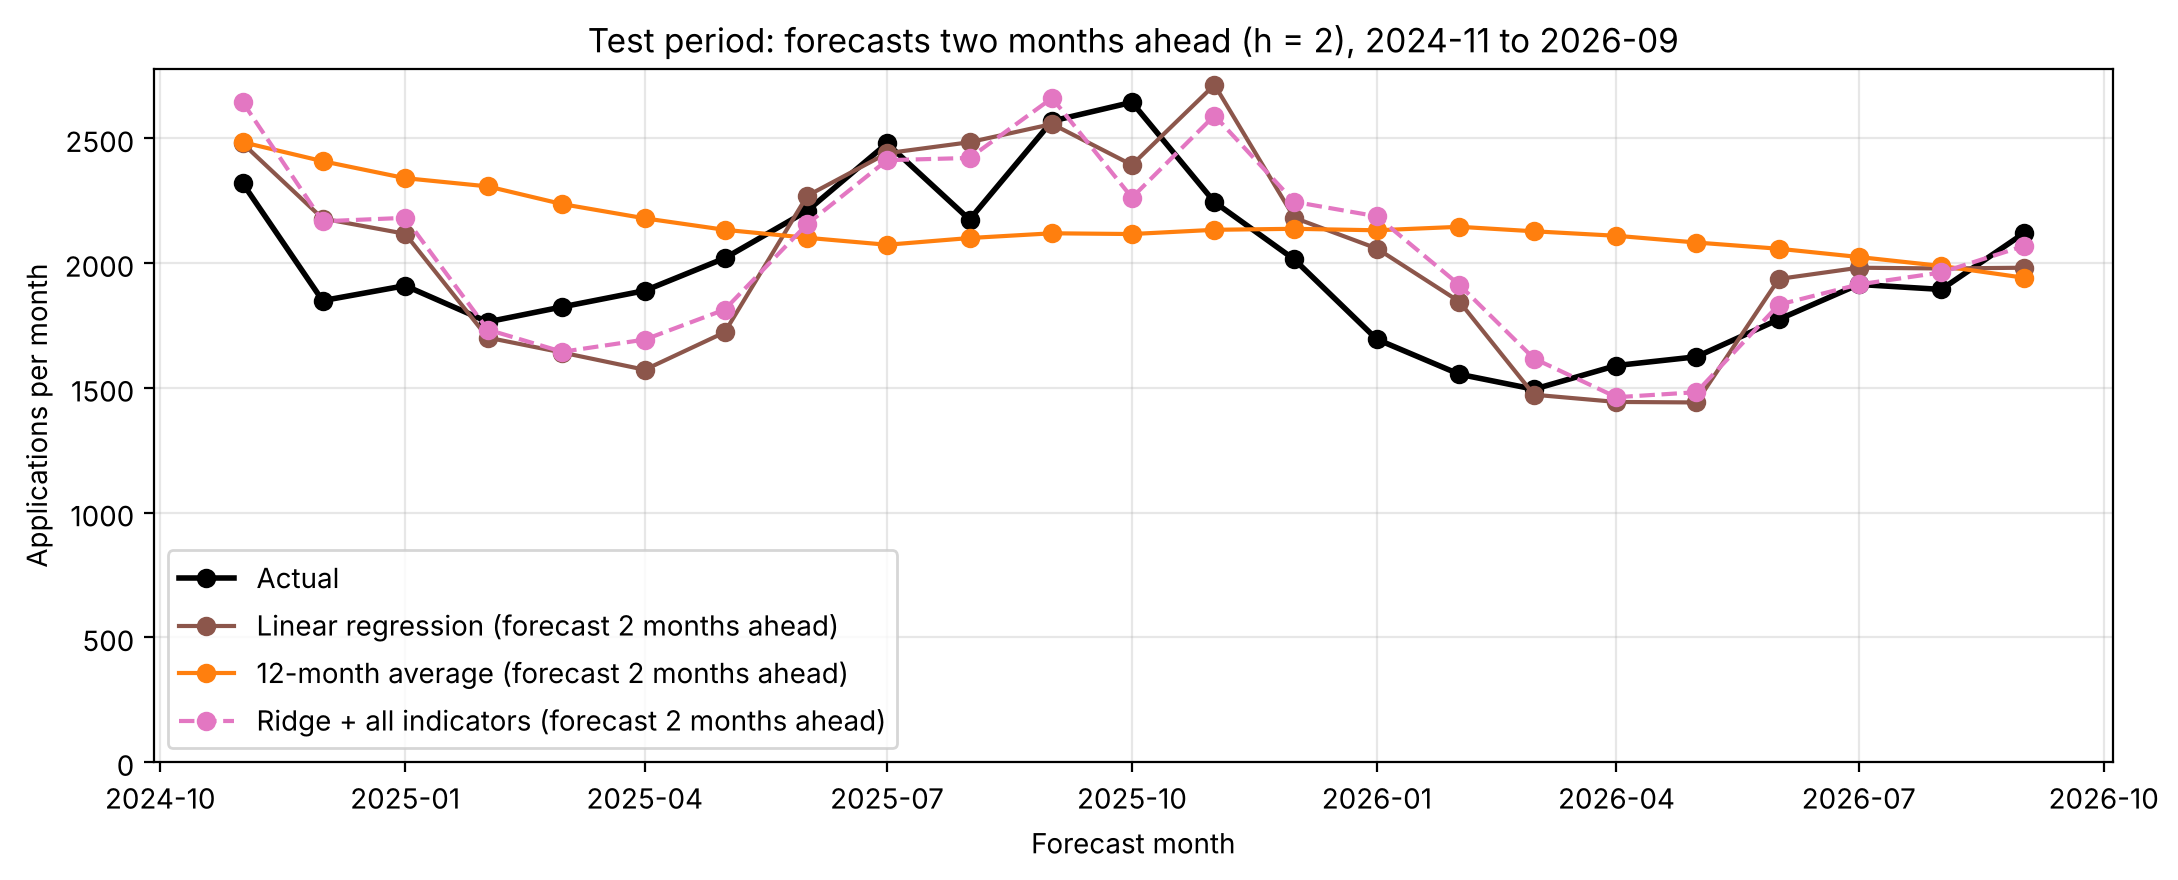

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly["Actual"], color="black", linewidth=2, marker="o", label="Actual")
ax.plot(monthly.index, monthly["Linear regression"], color=plt.cm.tab10(5), marker="o", label="Linear regression (forecast 2 months ahead)")
ax.plot(monthly.index, monthly["12-month average"], color=plt.cm.tab10(1), marker="o", label="12-month average (forecast 2 months ahead)")
ax.plot(monthly.index, monthly[model_2], color=plt.cm.tab10(6), marker="o", linestyle="--", label=f"{model_2} (forecast 2 months ahead)")
ax.set_title("Test period: forecasts two months ahead (h = 2), 2024-11 to 2026-09")
ax.set_xlabel("Forecast month")
ax.set_ylabel("Applications per month")
ax.set_ylim(bottom=0)
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/04_test_forecasts_h2.png")
plt.show()

**What we see.** The forecasts of the linear regression and of model 2 follow the actual numbers closely and are close to each other (on average 78 persons apart, at most 165). Both miss the largest month-to-month jumps by one or two months, as any model on past values does.

## 7. Which data help on the test months?

As in `03_evaluate.ipynb` (section 7): each regression against its own versions with indicators, on the test months, by MAE and MSE (log). Information only: the choice is fixed.

In [10]:
rows = []
for name in alpha_grids:
    for suffix in [" + routes", " + neighbours", " + conflict", " + all indicators"]:
        for h in [1, 2, 3]:
            a_ = test_errors[(test_errors["model"] == name + suffix) & (test_errors["h"] == h)].iloc[0]
            b_ = test_errors[(test_errors["model"] == name) & (test_errors["h"] == h)].iloc[0]
            rows.append({"indicators": suffix[3:], "model": name, "h": h,
                         "change in MAE (%)": 100 * (a_["MAE (persons)"] / b_["MAE (persons)"] - 1),
                         "change in MSE log (%)": 100 * (a_["MSE (log)"] / b_["MSE (log)"] - 1)})
pd.DataFrame(rows).pivot_table(index=["indicators", "model"], columns="h",
                               values=["change in MAE (%)", "change in MSE log (%)"], sort=False).round(1)

change in MAE (%)              \
h                                                1     2     3   
indicators     model                                             
routes         Linear regression               1.2   4.9   4.3   
               Ridge                          -0.9   0.2  -1.8   
               Lasso                          -1.3   0.5   3.2   
neighbours     Linear regression               2.9   3.0   5.0   
               Ridge                          -6.4  -3.3   0.9   
               Lasso                          -5.0  10.7   4.6   
conflict       Linear regression               3.7   1.3   6.5   
               Ridge                          -0.8   0.6   4.2   
               Lasso                          -1.5  -1.9   6.4   
all indicators Linear regression              11.8  12.9  16.1   
               Ridge                           8.0  -1.3   3.6   
               Lasso                           1.5   9.3  13.3   

                                 change in MSE log (%)              
h                                                    1     2     3  
indicators     model                                                
routes         Linear regression                  -1.7  -0.9   3.5  
               Ridge                               1.1  -0.7  -3.2  
               Lasso                               0.6 -12.8   2.5  
neighbours     Linear regression                  -0.9   1.0   4.2  
               Ridge                              -1.7  -0.4  -1.9  
               Lasso                              -0.1  10.8   9.1  
conflict       Linear regression                   5.5  -1.7  12.8  
               Ridge                               2.4   0.1   1.4  
               Lasso                              -3.5 -13.5  12.7  
all indicators Linear regression                  12.5   4.2  24.5  
               Ridge                              10.8  -1.4  12.6  
               Lasso                               8.4  -1.3  24.4

**What we see.** On the test months, adding indicators again gives no clear gain at $h = 2$: the changes in MAE range from −3.3% (Ridge with the neighbours) to +12.9% (linear regression with all three). The conflict index changes the MAE by −1.9% to +1.3%. Ridge with all indicators is 1.3% better than Ridge alone, the linear regression with all indicators 12.9% worse. No change reaches 10%, and with 23 test months such differences are small (a few persons per month). The lag of the conflict index chosen at the test origins mostly stays at 0 or 1.

## 8. Save the test forecasts

In [11]:
test_forecasts.drop(columns=["abs_error", "sq_error_log"]).to_csv("../data/processed/test_forecasts.csv", index=False)
print("Saved", test_forecasts.shape[0], "test forecasts")

Saved 1173 test forecasts


## Summary

- **Test period:** October 2024 to September 2026, used once; 23 forecasts per model at $h = 2$, all made with the months known at their origin.
- **Chosen model (linear regression):** MAE 188 persons at $h = 2$, **43% lower** than the 12-month average (331) and 30% lower than the random walk (269). The success rule is met.
- **Model 2 (Ridge with all indicators):** MAE 190, practically equal to the linear regression (1% apart).
- **Indicators:** no combination gives a clear gain on the test either (between −3% and +13% MAE); this confirms the backtest.
- **Test errors are smaller than backtest errors** because the test months were calm, not because the models became better.
- The choice made before the test stays: the linear regression on the series' own past.